In [1]:
import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

users = ["000", "001", "002", "003"]
base_path = "Geolife Trajectories 1.3/Data/"

all_data = []

print("Loading data")
for user in users:
    folder_path = os.path.join(base_path, user, "Trajectory")
    plt_files = glob.glob(os.path.join(folder_path, "*.plt"))

    if not plt_files:
        print(f"No plt files found in {user}")

    for file in plt_files:
        df = pd.read_csv(file, skiprows=6, header=None)
        df.columns = ["Latitude", "Longitude", "Reserved", "Altitude", "NumDays", "Date", "Time"]

        df["User_ID"] = user
        all_data.append(df)

data = pd.concat(all_data, ignore_index=True)
print("Data loaded")

Loading data
Data loaded


In [2]:
data["Datetime"] = pd.to_datetime(data["Date"] + " " + data["Time"])
data = data.drop(columns=["Reserved", "NumDays", "Date", "Time"])

data.dropna(subset=["Latitude", "Longitude"], inplace=True)
data = data[(data["Latitude"] >= -90) & (data["Latitude"] <= 90)]
data = data[(data["Longitude"] >= -180) & (data["Longitude"] <= 180)]

data = data.sort_values(by=["User_ID", "Datetime"]).reset_index(drop=True)

In [3]:
train_data_list = []
test_data_list = []

for user in data["User_ID"].unique():
    user_data = data[data["User_ID"] == user]
    split_idx = int(len(user_data) * 0.8)

    train_data_list.append(user_data.iloc[:split_idx])
    test_data_list.append(user_data.iloc[split_idx:])

train_df = pd.concat(train_data_list)
test_df = pd.concat(test_data_list)

print(f"Total records: {len(data)}")
print(f"Training records: {len(train_df)}")
print(f"Testing records: {len(test_df)}")

Total records: 1015920
Training records: 812734
Testing records: 203186


In [4]:
def k_means(X, K, max_iters=100, seed=42):
    np.random.seed(seed)

    random_indices = np.random.choice(len(X), size=K, replace=False)
    centroids = X[random_indices]

    for i in range(max_iters):
        distances = np.array([np.sqrt(np.sum((X - c)**2, axis=1)) for c in centroids])
        labels = np.argmin(distances, axis=0)

        new_centroids = np.zeros((K, X.shape[1]))
        for k in range(K):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                new_centroids[k] = np.mean(cluster_points, axis=0)
            else:
                new_centroids[k] = centroids[k]

        if np.all(centroids == new_centroids):
            print(f"K means converged at iteration {i + 1}")
            break

        centroids = new_centroids
    return centroids, labels

In [5]:
def predict(X, centroids):
    distances = np.array([np.sqrt(np.sum((X - c)**2, axis=1)) for c in centroids])
    return np.argmin(distances, axis=0)

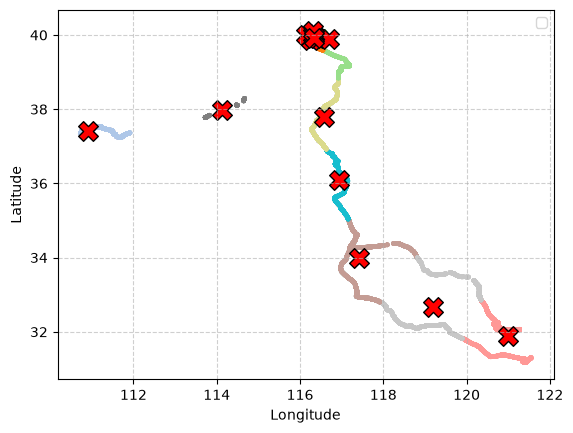

Cluster Centroids (Lat, Lon):
Cluster 0: (39.85967, 116.25676)
Cluster 1: (37.41270, 110.91966)
Cluster 2: (39.90798, 116.41085)
Cluster 3: (39.99934, 116.15393)
Cluster 4: (39.90517, 116.70390)
Cluster 5: (31.88287, 121.00113)
Cluster 6: (40.00536, 116.31806)
Cluster 7: (39.98584, 116.33050)
Cluster 8: (33.98809, 117.42593)
Cluster 9: (40.11124, 116.30521)
Cluster 10: (37.97807, 114.12687)
Cluster 11: (32.66627, 119.19831)
Cluster 12: (37.79820, 116.57855)
Cluster 13: (36.09031, 116.94556)
Cluster 14: (39.92460, 116.34194)


In [6]:
K = 15
X_train = train_df[["Latitude", "Longitude"]].values
centroids, train_labels = k_means(X_train, K)

train_df["Cluster_ID"] = train_labels
test_df["Cluster_ID"] = predict(test_df[["Latitude", "Longitude"]].values, centroids)

plt.scatter(train_df["Longitude"], train_df["Latitude"], c=train_df['Cluster_ID'], cmap='tab20', s=5)
plt.scatter(centroids[:, 1], centroids[:, 0], c='red', marker='X', s=200, edgecolors='black')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print("Cluster Centroids (Lat, Lon):")
for i, center in enumerate(centroids):
    print(f"Cluster {i}: ({center[0]:.5f}, {center[1]:.5f})")

In [7]:
import networkx as nx

def init_hmm_params(N, M, seed=42):
    np.random.seed(seed)
    pi = np.random.rand(N)
    pi /= np.sum(pi)
    
    # A: State transition matrix (N x N)
    A = np.random.rand(N, N)
    A /= np.sum(A, axis=1, keepdims=True)
    
    # B: Emission probability matrix (N x M)
    B = np.random.rand(N, M)
    B /= np.sum(B, axis=1, keepdims=True)
    
    return pi, A, B

In [8]:
def forward_scaled(obs_seq, pi, A, B):
    T = len(obs_seq)
    N = A.shape[0]
    alpha = np.zeros((T, N))
    c = np.zeros(T)
    
    # Base case (t=0)
    alpha[0] = pi * B[:, obs_seq[0]]
    c[0] = np.sum(alpha[0])
    if c[0] == 0: c[0] = 1e-10
    alpha[0] /= c[0]
    
    # Inductive step (t > 0)
    for t in range(1, T):
        alpha[t] = np.dot(alpha[t-1], A) * B[:, obs_seq[t]]
        c[t] = np.sum(alpha[t])
        if c[t] == 0: c[t] = 1e-10
        alpha[t] /= c[t]
        
    return alpha, c

In [9]:
def backward_scaled(obs_seq, A, B, c):
    T = len(obs_seq)
    N = A.shape[0]
    beta = np.zeros((T, N))
    
    # Base case (t=T-1)
    beta[T-1] = 1.0 / c[T-1]
    
    # Inductive step (t < T-1)
    for t in range(T-2, -1, -1):
        beta[t] = np.dot(A, B[:, obs_seq[t+1]] * beta[t+1])
        beta[t] /= c[t]
        
    return beta

In [10]:
def train_hmm_baum_welch(obs_sequences, N, M, max_iter=10):
    pi, A, B = init_hmm_params(N, M)
    
    print(f"Training HMM with {N} hidden states using Baum-Welch...")
    
    for iteration in range(max_iter):
        pi_num = np.zeros(N)
        A_num = np.zeros((N, N))
        A_den = np.zeros(N)
        B_num = np.zeros((N, M))
        B_den = np.zeros(N)
        
        for obs_seq in obs_sequences:
            T = len(obs_seq)
            if T < 2: continue
                
            alpha, c = forward_scaled(obs_seq, pi, A, B)
            beta = backward_scaled(obs_seq, A, B, c)
            
            gamma = alpha * beta * c[:, np.newaxis]
            gamma /= np.sum(gamma, axis=1, keepdims=True)
            
            xi = np.zeros((T-1, N, N))
            for t in range(T-1):
                xi[t] = (alpha[t, :].reshape(-1, 1) * A * 
                         B[:, obs_seq[t+1]].reshape(1, -1) * 
                         beta[t+1, :].reshape(1, -1))
                xi_sum = np.sum(xi[t])
                if xi_sum > 0:
                    xi[t] /= xi_sum
                
            pi_num += gamma[0]
            A_num += np.sum(xi, axis=0)
            A_den += np.sum(gamma[:-1], axis=0)
            
            for t in range(T):
                B_num[:, obs_seq[t]] += gamma[t]
            B_den += np.sum(gamma, axis=0)
            
        pi = pi_num / np.sum(pi_num)
        A = A_num / A_den[:, np.newaxis]
        B = B_num / B_den[:, np.newaxis]
        
        print(f"Iteration {iteration + 1} complete.")
        
    return pi, A, B

In [11]:
train_obs_sequences = [train_df[train_df["User_ID"] == u]["Cluster_ID"].values for u in train_df['User_ID'].unique()]
N_HIDDEN_STATES = 5 
M_OBSERVATIONS = K
pi, A, B = train_hmm_baum_welch(train_obs_sequences, N_HIDDEN_STATES, M_OBSERVATIONS)

Training HMM with 5 hidden states using Baum-Welch...
Iteration 1 complete.
Iteration 2 complete.
Iteration 3 complete.
Iteration 4 complete.
Iteration 5 complete.
Iteration 6 complete.
Iteration 7 complete.
Iteration 8 complete.
Iteration 9 complete.
Iteration 10 complete.


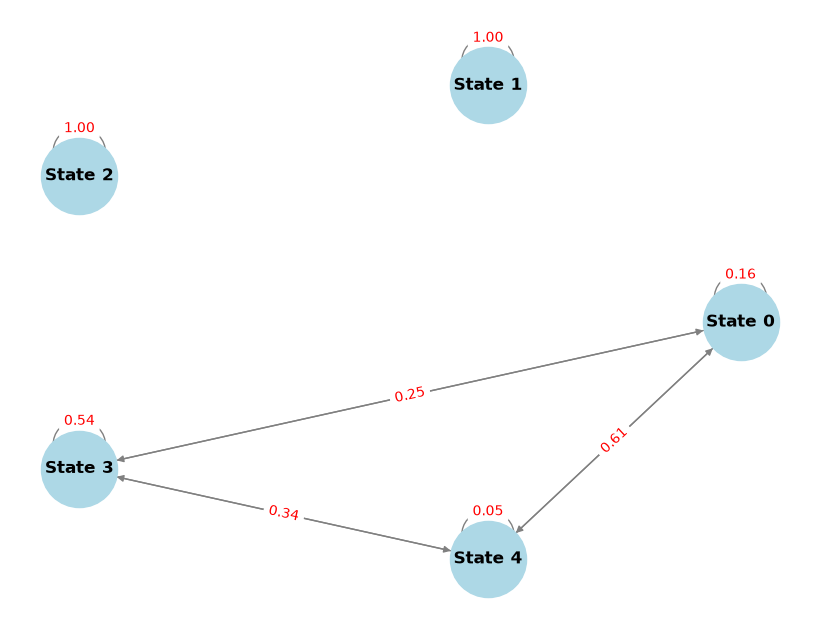

In [12]:
def plot_hmm_transitions(A, N):
    plt.figure(figsize=(8, 6))
    G = nx.DiGraph()
    
    for i in range(N):
        G.add_node(f"State {i}")
        
    for i in range(N):
        for j in range(N):
            if A[i, j] > 0.05:
                G.add_edge(f"State {i}", f"State {j}", weight=A[i, j])
                
    pos = nx.circular_layout(G)
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=3000, 
            font_size=12, font_weight='bold', edge_color='gray', arrows=True)
    
    edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red')
    plt.show()

plot_hmm_transitions(A, N_HIDDEN_STATES)

In [13]:
import time
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Haversine Distance Calculation (in meters)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371000.0  # Radius of Earth in meters
    
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    return R * c

In [14]:
def viterbi(obs_seq, pi, A, B):
    T = len(obs_seq)
    N = A.shape[0]
    
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    
    # Initialization
    delta[0] = pi * B[:, obs_seq[0]]
    delta[0] /= np.sum(delta[0]) + 1e-10 # Normalize to prevent underflow
    
    # Recursion
    for t in range(1, T):
        for j in range(N):
            transitions = delta[t-1] * A[:, j]
            psi[t, j] = np.argmax(transitions)
            delta[t, j] = np.max(transitions) * B[j, obs_seq[t]]
        delta[t] /= np.sum(delta[t]) + 1e-10
        
    # Backtracking
    states = np.zeros(T, dtype=int)
    states[T-1] = np.argmax(delta[T-1])
    
    for t in range(T-2, -1, -1):
        states[t] = psi[t+1, states[t+1]]
        
    return states

In [15]:
def predict_next_location(obs_seq, pi, A, B):
    # 1. Estimate probability distribution over current hidden states
    alpha, _ = forward_scaled(obs_seq, pi, A, B)
    current_state_prob = alpha[-1]
    
    # 2. Predict the hidden state at the next time step
    next_state_prob = np.dot(current_state_prob, A)
    
    # 3. Estimate probability distribution of the next observed location cluster
    next_obs_prob = np.dot(next_state_prob, B)
    
    # 4. Identify most probable next locations
    top_3_clusters = np.argsort(next_obs_prob)[::-1][:3]
    top_1_cluster = top_3_clusters[0]
    
    return top_1_cluster, top_3_clusters

In [16]:
print("Starting prediction evaluation on test set...")
start_time = time.time()

actual_clusters = []
top1_predictions = []
top3_predictions = []
distances = []

Starting prediction evaluation on test set...


In [17]:
user_test_df = test_df[test_df['User_ID'] == users[0]].reset_index(drop=True)
test_obs_seq = user_test_df['Cluster_ID'].values

evaluation_limit = min(100, len(test_obs_seq) - 1)
history_window = 10 # Predict using the last 10 observations

for t in range(history_window, evaluation_limit):
    # Historical trajectory up to time t
    history_seq = test_obs_seq[t-history_window : t]
    
    # Actual next location
    actual_next_cluster = test_obs_seq[t]
    actual_lat = user_test_df.loc[t, 'Latitude']
    actual_lon = user_test_df.loc[t, 'Longitude']
    
    # Predict
    top1_pred, top3_pred = predict_next_location(history_seq, pi, A, B)
    
    # Convert predicted cluster ID to geographical centroid
    pred_lat, pred_lon = centroids[top1_pred]
    
    # Calculate Haversine distance
    dist = haversine(actual_lat, actual_lon, pred_lat, pred_lon)
    
    # Record metrics
    actual_clusters.append(actual_next_cluster)
    top1_predictions.append(top1_pred)
    top3_predictions.append(actual_next_cluster in top3_pred)
    distances.append(dist)

exec_time = time.time() - start_time

In [18]:
top1_accuracy = np.mean(np.array(actual_clusters) == np.array(top1_predictions))
top3_accuracy = np.mean(top3_predictions)
precision = precision_score(actual_clusters, top1_predictions, average='weighted', zero_division=0)
recall = recall_score(actual_clusters, top1_predictions, average='weighted', zero_division=0)
f1 = f1_score(actual_clusters, top1_predictions, average='weighted', zero_division=0)
mean_distance = np.mean(distances)

print("\n--- Performance Evaluation Metrics ---")
print(f"Top-1 Accuracy:     {top1_accuracy * 100:.2f}%")
print(f"Top-3 Accuracy:     {top3_accuracy * 100:.2f}%")
print(f"Precision:          {precision:.4f}")
print(f"Recall:             {recall:.4f}")
print(f"F1-score:           {f1:.4f}")
print(f"Haversine Distance: {mean_distance:.2f} meters")
print(f"Execution Time:     {exec_time:.2f} seconds")


--- Performance Evaluation Metrics ---
Top-1 Accuracy:     100.00%
Top-3 Accuracy:     100.00%
Precision:          1.0000
Recall:             1.0000
F1-score:           1.0000
Haversine Distance: 3676.19 meters
Execution Time:     17.07 seconds


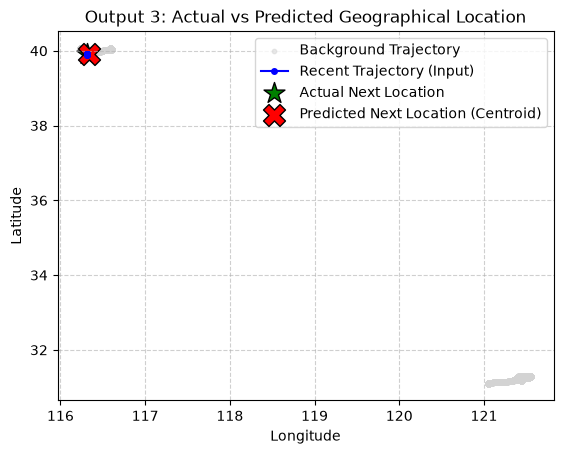

In [19]:
plt.scatter(user_test_df['Longitude'], user_test_df['Latitude'], 
            c='lightgray', s=10, label='Background Trajectory', alpha=0.5)

# Plot historical path leading up to prediction
history_lats = user_test_df.loc[t-history_window : t-1, 'Latitude']
history_lons = user_test_df.loc[t-history_window : t-1, 'Longitude']
plt.plot(history_lons, history_lats, c='blue', marker='o', markersize=4, label='Recent Trajectory (Input)')

# Plot Actual vs Predicted Next Location
plt.scatter(actual_lon, actual_lat, c='green', marker='*', s=250, edgecolors='black', label='Actual Next Location')
plt.scatter(pred_lon, pred_lat, c='red', marker='X', s=250, edgecolors='black', label='Predicted Next Location (Centroid)')

plt.title('Output 3: Actual vs Predicted Geographical Location')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()